# Fine-Tuning Chatbot Bahasa Indonesia dengan QLoRA

Notebook ini membangun **satu chatbot generatif bahasa Indonesia** menggunakan **Qwen2.5-1.5B-Instruct** dan *Supervised Fine-Tuning* (SFT) berbasis **QLoRA 4-bit**. Pipeline mengikuti alur dataset → preprocessing → training → validasi → inferensi → unggah model lengkap ke Hugging Face Hub. Seluruh pekerjaan dikerjakan pada **Google Colab GPU**, tanpa identitas pribadi atau username yang ditulis dalam kode.

**Sumber utama:**

- **Dataset:** [OpenPathAI/alpaca-gpt4-indonesian-cleaned](https://huggingface.co/datasets/OpenPathAI/alpaca-gpt4-indonesian-cleaned) — pasangan `prompt` dan `response` dalam bahasa Indonesia.
- **Base model:** [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct) — model bahasa generatif berlisensi Apache-2.0.
- **Checkpoint training 4-bit:** [unsloth/Qwen2.5-1.5B-Instruct-bnb-4bit](https://huggingface.co/unsloth/Qwen2.5-1.5B-Instruct-bnb-4bit).
- **Acuan teknis:** [Unsloth Google Colab](https://unsloth.ai/docs/get-started/install/google-colab), [TRL SFTTrainer](https://huggingface.co/docs/trl/sft_trainer), dan [Hugging Face Hub](https://huggingface.co/docs/huggingface_hub/en/quick-start).

## 01. Instalasi Dependensi

Unsloth digunakan untuk *fine-tuning* dan ekspor model secara hemat memori. Jalankan satu kali pada runtime Colab baru; jika diminta, lakukan *restart session*, lalu lanjutkan dari sel import.

In [2]:
# Install Unsloth dan pustaka pelatihan yang kompatibel melalui dependensi resminya.
%pip -q install -U --no-cache-dir "unsloth[huggingface]" "huggingface_hub>=0.34" "pandas>=2.0" "matplotlib>=3.8"

## 02. Import dan Pemeriksaan Runtime

Memuat pustaka, mengatur seed untuk reproduksibilitas, dan memeriksa GPU. Training tidak dilanjutkan apabila runtime tidak memiliki CUDA.

In [3]:
# Unsloth perlu diimpor sebelum transformers dan trl agar patch training aktif.
import unsloth
from unsloth import FastLanguageModel

import gc
import json
import os
import random
import re
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from huggingface_hub import HfApi
from IPython.display import display
from transformers import set_seed
from trl import SFTConfig, SFTTrainer
from google.colab import userdata

# Kunci seed dan atur environment secara konsisten.
SEED = 3407
random.seed(SEED)
np.random.seed(SEED)
set_seed(SEED)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

# Pastikan runtime memiliki GPU NVIDIA CUDA.
if not torch.cuda.is_available():
    raise RuntimeError("CUDA belum aktif. Pilih Runtime > Change runtime type > T4 GPU.")

GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEMORY_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU:", GPU_NAME)
print(f"VRAM: {GPU_MEMORY_GB:.1f} GB")
print("Precision:", COMPUTE_DTYPE)
print("Seed:", SEED)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU: Tesla T4
VRAM: 14.6 GB
Precision: torch.float16
Seed: 3407


## 03. Autentikasi Hugging Face

Token dibaca dari **Colab Secrets**, bukan ditulis langsung dalam notebook. Identitas namespace repository diperoleh secara otomatis dari akun token yang aktif. Kode hanya menampilkan status autentikasi dan URL model, bukan isi token.

In [4]:
# Hugging Face authentication
HF_TOKEN = userdata.get("HF_TOKEN")

if not HF_TOKEN or not HF_TOKEN.startswith("hf_"):
    raise RuntimeError("Secret HF_TOKEN belum tersedia atau tidak valid.")

# Hugging Face account configuration
HF_USERNAME = "Lukas16"
HF_MODEL_NAME = "qwen2-5-1-5b-indonesian-chatbot-sft"
HF_REPO_ID = f"{HF_USERNAME}/{HF_MODEL_NAME}"
HF_REPO_PRIVATE = False

# Validate token and account
hf_api = HfApi(token=HF_TOKEN)
account = hf_api.whoami()

if account["name"] != HF_USERNAME:
    raise RuntimeError(
        f"Token terhubung ke akun {account['name']}, "
        f"bukan {HF_USERNAME}."
    )

# Display repository information
print("Hugging Face authentication: Successful")
print(f"Account: {HF_USERNAME}")
print(f"Repository: https://huggingface.co/{HF_REPO_ID}")
print(f"Private repository: {HF_REPO_PRIVATE}")

Hugging Face authentication: Successful
Account: Lukas16
Repository: https://huggingface.co/Lukas16/qwen2-5-1-5b-indonesian-chatbot-sft
Private repository: False


## 04. Konfigurasi Training

Satu konfigurasi digunakan hingga selesai, tanpa beberapa eksperimen. Dua epoch dan learning rate konservatif dipilih sebagai titik awal *instruction tuning* pada model yang sudah *instruct-tuned*. Semua lokasi output hanya berada di runtime Colab yang bersifat sementara.

In [5]:
# Sumber dataset dan model.
DATASET_ID = "OpenPathAI/alpaca-gpt4-indonesian-cleaned"
MODEL_ID = "unsloth/Qwen2.5-1.5B-Instruct-bnb-4bit"
BASE_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DATASET_FILENAME = "alpaca-gpt4-indonesian-cleaned.csv"

# Jumlah contoh untuk satu training run.
TRAIN_ROWS = 5000
VALIDATION_ROWS = 300
TEST_ROWS = 100
CANDIDATE_ROWS = 16000
MAX_SEQ_LENGTH = 1024

# Parameter QLoRA dan optimizer.
LORA_RANK = 32
LORA_ALPHA = 64
LORA_DROPOUT = 0.0
LEARNING_RATE = 1e-4
EPOCHS = 2
TRAIN_BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 4
EVAL_BATCH_SIZE = 2
WARMUP_RATIO = 0.05
WEIGHT_DECAY = 0.01
LOGGING_STEPS = 25
EVAL_SAVE_STEPS = 250

# Tempat CSV dan checkpoint sementara saat Colab masih aktif.
WORK_DIR = Path("/content/indonesian_chatbot_sft")
DATA_DIR = WORK_DIR / "data"
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
for path in (DATA_DIR, CHECKPOINT_DIR):
    path.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / DATASET_FILENAME

config_table = pd.DataFrame([
    ("Base model", BASE_MODEL_ID),
    ("Dataset", DATASET_ID),
    ("Train / validation / test", f"{TRAIN_ROWS} / {VALIDATION_ROWS} / {TEST_ROWS}"),
    ("Sequence length", MAX_SEQ_LENGTH),
    ("LoRA rank / alpha", f"{LORA_RANK} / {LORA_ALPHA}"),
    ("Learning rate", LEARNING_RATE),
    ("Epoch", EPOCHS),
    ("Effective batch size", TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION),
    ("Model destination", HF_REPO_ID),
], columns=["Komponen", "Pengaturan"])
display(config_table)

,Komponen,Pengaturan
0,Base model,Qwen/Qwen2.5-1.5B-Instruct
1,Dataset,OpenPathAI/alpaca-gpt4-indonesian-cleaned
2,Train / validation / test,5000 / 300 / 100
3,Sequence length,1024
4,LoRA rank / alpha,32 / 64
5,Learning rate,0.0001
6,Epoch,2
7,Effective batch size,8
8,Model destination,Lukas16/qwen2-5-1-5b-indonesian-chatbot-sft


## 05. Unduh Dataset Publik dan Simpan CSV

Dataset diunduh dari Hugging Face kemudian ditulis sebagai CSV dengan nama dataset aslinya. File berada di `/content` dan **hanya sementara**; CSV inilah yang digunakan untuk preprocessing selanjutnya.

In [6]:
# Ambil dataset publik dan simpan seluruh baris dalam format CSV.
raw_dataset = load_dataset(DATASET_ID, split="train")
raw_df = raw_dataset.to_pandas()

# Periksa skema sebelum menulis CSV.
required_columns = {"prompt", "response"}
if not required_columns.issubset(raw_df.columns):
    raise ValueError(f"Kolom dataset tidak sesuai: {list(raw_df.columns)}")

raw_df.to_csv(CSV_PATH, index=False, encoding="utf-8-sig")
print("Dataset tersimpan sementara:", CSV_PATH)
print("Total baris:", len(raw_df))
print(f"Ukuran CSV: {CSV_PATH.stat().st_size / (1024 ** 2):.2f} MB")

README.md:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.7MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset tersimpan sementara: /content/indonesian_chatbot_sft/data/alpaca-gpt4-indonesian-cleaned.csv
Total baris: 48322
Ukuran CSV: 38.25 MB


## 06. Preview Dataset dan Pemeriksaan Awal

Menampilkan contoh instruksi dan target respons tanpa mencetak seluruh teks panjang. Periksa apakah pasangan pertanyaan–jawaban masih wajar untuk digunakan sebagai data SFT.

In [7]:
# Muat ulang dari CSV untuk memastikan file dapat digunakan.
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig", keep_default_na=False)
print("Kolom:", list(df.columns))
print("Baris:", len(df))
print("Prompt kosong:", (df["prompt"].astype(str).str.strip() == "").sum())
print("Response kosong:", (df["response"].astype(str).str.strip() == "").sum())

# Tampilkan beberapa contoh dalam panjang teks terbatas.
preview = df[["prompt", "response"]].sample(n=min(5, len(df)), random_state=SEED).copy()
preview["prompt"] = preview["prompt"].astype(str).str.slice(0, 140)
preview["response"] = preview["response"].astype(str).str.slice(0, 260)
display(preview.reset_index(drop=True))

Kolom: ['prompt', 'response']
Baris: 48322
Prompt kosong: 0
Response kosong: 0


,prompt,response
0,Tulis kembali kalimat tersebut agar menggunaka...,Saya ingin menekankan pada titik ini.
1,"Diberikan kode berikut, temukan output dan jel...","Hasil keluaran dari kode ini adalah ""Benar"". L..."
2,Buatlah sebuah surat terbuka yang persuasif. K...,"Hormat yang terhormat, Sebagai kecerdasan buat..."
3,"Diberikan deskripsi produk, buatlah 5 kasus pe...",1. Pelanggan toko online dapat menggunakan cha...
4,Buatlah sebuah melodi dengan nada C-E-G-B.,Tentu saja! Di sini adalah satu melodi yang mu...


## 07. Pembersihan dan Deduplicasi

Membersihkan karakter kontrol, respons kosong, teks yang terlalu pendek, dan pertanyaan duplikat. Langkah ini hanya memvalidasi format; kualitas faktual jawaban tetap perlu ditinjau secara terpisah.

In [8]:
def clean_text(value):
    # Normalisasi Unicode tanpa menghapus tanda baca yang bermakna.
    text = unicodedata.normalize("NFKC", str(value)).strip()
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", "", text)
    return text

# Bersihkan pasangan teks dan hilangkan jawaban tidak valid.
clean_df = df[["prompt", "response"]].copy()
clean_df["prompt"] = clean_df["prompt"].map(clean_text)
clean_df["response"] = clean_df["response"].map(clean_text)
clean_df = clean_df[
    clean_df["prompt"].str.len().ge(12)
    & clean_df["response"].str.len().ge(30)
].copy()
clean_df = clean_df[
    ~clean_df["response"].str.lower().isin({"n/a", "none", "null", "tidak ada"})
].copy()

# Mencegah prompt yang sama bocor ke train dan validation/test.
clean_df["dedup_key"] = clean_df["prompt"].str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
clean_df = clean_df.drop_duplicates(subset="dedup_key", keep="first").reset_index(drop=True)
clean_df = clean_df.drop(columns="dedup_key")

print("Baris awal:", len(df))
print("Baris setelah cleaning:", len(clean_df))
display(clean_df.head(3))

Baris awal: 48322
Baris setelah cleaning: 47271


,prompt,response
0,Saranlah slogan untuk kampanye daur ulang,"1. ""Kurangi, gunakan kembali, daur ulang: Bers..."
1,Ciptakan cara unik dan lucu untuk menggambarka...,"Sebagai AI, saya tidak tergabung dalam satu ne..."
2,"Diberikan deskripsi tentang peristiwa pribadi,...",Lautan membiru cemerlang Terang matahari di at...


## 08. Load Model, Tokenizer, dan Panjang Teks

Model Qwen dalam format 4-bit digunakan untuk menekan kebutuhan GPU Colab. Sebelum training, panjang token setiap pasangan diperiksa agar respons yang terlalu panjang **tidak terpotong** saat perhitungan loss.

In [9]:
# Unsloth memuat model 4-bit yang sesuai untuk QLoRA.
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_ID,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
)

# Pastikan tokenizer memiliki padding token.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Format dua pesan mengikuti chat template bawaan Qwen.
def to_messages(question, answer):
    return [
        {"role": "user", "content": str(question)},
        {"role": "assistant", "content": str(answer)},
    ]

def token_count(question, answer):
    ids = tokenizer.apply_chat_template(
        to_messages(question, answer),
        tokenize=True,
        add_generation_prompt=False,
    )
    return len(ids)

# Ambil kandidat acak terlebih dahulu untuk membatasi waktu preprocessing.
candidates = clean_df.sample(
    n=min(CANDIDATE_ROWS, len(clean_df)),
    random_state=SEED,
).reset_index(drop=True)

candidates["token_count"] = [
    token_count(row.prompt, row.response)
    for row in candidates.itertuples(index=False)
]

length_stats = candidates["token_count"].describe(percentiles=[0.5, 0.9, 0.95, 0.99])
display(length_stats.to_frame(name="token_count"))
print("Kandidat yang melewati batas:", int((candidates["token_count"] > MAX_SEQ_LENGTH).sum()))

==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

,token_count
count,16000.000000
mean,274.196563
std,191.913506
min,47.000000
50%,222.000000
90%,562.000000
95%,643.050000
99%,785.010000
max,1561.000000


Kandidat yang melewati batas: 3


## 09. Filter Panjang dan Split Dataset

Hanya data yang muat penuh di batas 1.024 token yang digunakan. Train, validation, dan test dipisah berdasarkan prompt unik sebelum training. CSV olahan juga dibuat di Colab untuk memudahkan pemeriksaan.

In [10]:
# Hanya gunakan pasangan dengan pertanyaan dan jawaban lengkap.
eligible_df = candidates[
    candidates["token_count"].le(MAX_SEQ_LENGTH)
].drop(columns="token_count").reset_index(drop=True)

needed = TRAIN_ROWS + VALIDATION_ROWS + TEST_ROWS
if len(eligible_df) < needed:
    raise RuntimeError(
        f"Data layak hanya {len(eligible_df)} baris, perlu {needed}. "
        "Naikkan CANDIDATE_ROWS atau kurangi jumlah sampel."
    )

# Urutkan acak secara deterministik lalu pisahkan data.
selected = eligible_df.sample(n=needed, random_state=SEED).reset_index(drop=True)
train_df = selected.iloc[:TRAIN_ROWS].copy()
validation_df = selected.iloc[TRAIN_ROWS:TRAIN_ROWS + VALIDATION_ROWS].copy()
test_df = selected.iloc[TRAIN_ROWS + VALIDATION_ROWS:].copy()

# Simpan CSV dataset olahan pada disk sementara Colab.
for name, frame in [("train", train_df), ("validation", validation_df), ("test", test_df)]:
    frame.to_csv(DATA_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"{name}: {len(frame)} baris")

# Pastikan tidak ada prompt yang sama antara split.
train_prompts = set(train_df["prompt"].str.casefold())
val_prompts = set(validation_df["prompt"].str.casefold())
test_prompts = set(test_df["prompt"].str.casefold())
assert train_prompts.isdisjoint(val_prompts)
assert train_prompts.isdisjoint(test_prompts)
assert val_prompts.isdisjoint(test_prompts)

train: 5000 baris
validation: 300 baris
test: 100 baris


## 10. Format Dataset untuk SFT

Pasangan pertanyaan–jawaban dikonversi menjadi *conversational prompt-completion dataset*. TRL menghitung **loss pada bagian respons asisten saja** (`completion_only_loss=True`), bukan pada kata-kata pertanyaan pengguna.

In [11]:
def make_sft_records(frame):
    # Simpan pesan pengguna dan respons sebagai dua bagian terpisah.
    return [
        {
            "prompt": [{"role": "user", "content": row.prompt}],
            "completion": [{"role": "assistant", "content": row.response}],
        }
        for row in frame.itertuples(index=False)
    ]

train_dataset = Dataset.from_list(make_sft_records(train_df))
validation_dataset = Dataset.from_list(make_sft_records(validation_df))

print("Training records:", len(train_dataset))
print("Validation records:", len(validation_dataset))
print("Contoh struktur:")
print(json.dumps(train_dataset[0], ensure_ascii=False, indent=2)[:850])

Training records: 5000
Validation records: 300
Contoh struktur:
{
  "prompt": [
    {
      "content": "Buatlah skrip dengan menggunakan struktur cerita klasik.",
      "role": "user"
    }
  ],
  "completion": [
    {
      "content": "Dahulu kala, di sebuah kerajaan jauh, hiduplah seorang putri cantik bernama Rose. Dia baik hati dan lembut, dan semua orang di kerajaan menyayanginya. Namun, suatu hari, seorang penyihir jahat melemparkan mantra padanya, dan dia terjatuh dalam tidur yang sangat panjang. Sang penyihir, dipenuhi oleh keserakahan, memutuskan untuk mengambil alih kerajaan saat sang putri tertidur. Kerajaan itu berada dalam kekacauan; orang-orang menderita, dan harapan tampak hilang. Namun, tanpa disadari oleh penyihir, ada seorang ksatria berani bernama Daniel yang sedang dalam misi untuk menyelamatkan sang putri dan mengembalikan perdamaian ke kerajaan. Daniel menghadapi banyak tantangan 


## 11. Konfigurasi QLoRA

Menambahkan LoRA pada proyeksi attention dan MLP. Model utama tetap dikompresi 4-bit ketika training; hanya parameter adapter yang diperbarui sehingga konsumsi VRAM lebih rendah daripada full fine-tuning.

In [12]:
# Tentukan proyeksi linear Qwen untuk adaptasi LoRA.
TARGET_MODULES = [
    "q_proj", "k_proj", "v_proj", "o_proj",
    "gate_proj", "up_proj", "down_proj",
]

model = FastLanguageModel.get_peft_model(
    model,
    r=LORA_RANK,
    target_modules=TARGET_MODULES,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
    use_rslora=False,
    loftq_config=None,
)

model.print_trainable_parameters()

Unsloth 2026.10.8 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 36,929,536 || all params: 1,580,643,840 || trainable%: 2.3364


## 12. Training Configuration dan Pemeriksaan Loss

Training dilakukan **sekali** selama dua epoch dengan *cosine schedule*, warmup, evaluasi berkala, dan checkpoint sementara. `load_best_model_at_end` memilih checkpoint berdasarkan validation loss. Pemeriksaan label memastikan token pertanyaan tidak dipakai menghitung loss.

In [13]:
# SFTConfig mengatur satu training run beserta evaluasinya.
training_args = SFTConfig(
    output_dir=str(CHECKPOINT_DIR),
    dataset_text_field="text",
    max_length=MAX_SEQ_LENGTH,
    packing=False,
    completion_only_loss=True,
    assistant_only_loss=False,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    optim="adamw_8bit",
    fp16=COMPUTE_DTYPE == torch.float16,
    bf16=COMPUTE_DTYPE == torch.bfloat16,
    logging_strategy="steps",
    logging_steps=LOGGING_STEPS,
    logging_first_step=True,
    eval_strategy="steps",
    eval_steps=EVAL_SAVE_STEPS,
    save_strategy="steps",
    save_steps=EVAL_SAVE_STEPS,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    push_to_hub=False,
)

trainer = SFTTrainer(
    model=model,
    processing_class=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    args=training_args,
)

# Validasi masking token sebelum training panjang dimulai.
batch = next(iter(trainer.get_train_dataloader()))
labels = batch["labels"]
valid_tokens = int((labels != -100).sum().item())
ignored_tokens = int((labels == -100).sum().item())
assert valid_tokens > 0, "Tidak ada token target untuk dilatih. Periksa format dataset dan tokenizer."
assert ignored_tokens > 0, "Prompt belum termasking. Periksa completion_only_loss dan format dataset."
print("Token respons yang dihitung:", valid_tokens)
print("Token prompt/padding yang diabaikan:", ignored_tokens)
print("Target global steps (perkiraan):", (len(train_dataset) * EPOCHS + TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION - 1) // (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION))

Unsloth: transformers renamed `warmup_ratio` to `warmup_steps`. Forwarding your value to `warmup_steps` - update your code when convenient. If you also passed `warmup_steps` as 0.1, that is its default here and cannot be distinguished from leaving it unset, so `warmup_ratio` was used; drop `warmup_ratio` to keep it.


Unsloth: Tokenizing ["prompt"+"completion"] (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

Unsloth: Building labels for train dataset (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["prompt"+"completion"] (num_proc=2):   0%|          | 0/300 [00:00<?, ? examples/s]

Unsloth: Building labels for eval dataset (num_proc=2):   0%|          | 0/300 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Token respons yang dihitung: 601
Token prompt/padding yang diabaikan: 91
Target global steps (perkiraan): 1250


## 13. Fine-Tuning

Satu sesi training dijalankan sampai selesai. Checkpoint berada di disk sementara Colab dan hanya dipakai untuk memilih bobot terbaik; model final nanti diunggah ke Hugging Face Hub.

In [14]:
# Latih model satu kali dengan konfigurasi yang sudah ditentukan.
train_result = trainer.train()
validation_metrics = trainer.evaluate()

print("Training selesai.")
print("Global steps:", trainer.state.global_step)
print("Training loss:", round(float(train_result.training_loss), 4))
print("Validation loss:", round(float(validation_metrics["eval_loss"]), 4))
print("Best checkpoint:", trainer.state.best_model_checkpoint)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,000 | Num Epochs = 2 | Total steps = 1,250
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 36,929,536 of 1,580,643,840 (2.34% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
250,1.409040,1.321393
500,1.360817,1.288635
750,1.149308,1.280153
1000,1.171304,1.273250
1250,1.144605,1.269847


Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Qwen2ForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in /content/indonesian_chatbot_sft/checkpoints/checkpoint-250/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/indonesian_chatbot_sft/checkpoints/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/indonesian_chatbot_sft/checkpoints/checkpoint-750/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/indonesian_chatbot_sft/checkpoints/checkpoint-1000/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/indonesian_chatbot_sft/checkpoints/checkpoint-1250/tokenizer_config.json.


Training Loss,Validation Loss,Step
1.144605,1.269847,1250


Training selesai.
Global steps: 1250
Training loss: 1.2663
Validation loss: 1.2698
Best checkpoint: /content/indonesian_chatbot_sft/checkpoints/checkpoint-1250


## 14. Dokumentasi Training

Mengubah riwayat training menjadi tabel dan grafik untuk melihat pergerakan loss. Grafik berikut adalah **dokumentasi satu training run**, bukan perbandingan beberapa eksperimen.

,step,epoch,loss,eval_loss,learning_rate
0,1050,1.68,1.180718,NaN,6.909776e-06
1,1075,1.72,1.138361,NaN,5.327170e-06
2,1100,1.76,1.126310,NaN,3.940072e-06
3,1125,1.80,1.181172,NaN,2.754551e-06
4,1150,1.84,1.189812,NaN,1.775797e-06
5,1175,1.88,1.145391,NaN,1.008093e-06
6,1200,1.92,1.153197,NaN,4.547987e-07
7,1225,1.96,1.189648,NaN,1.183351e-07
8,1250,2.00,1.144605,NaN,1.751209e-10
9,1250,2.00,NaN,1.269847,NaN


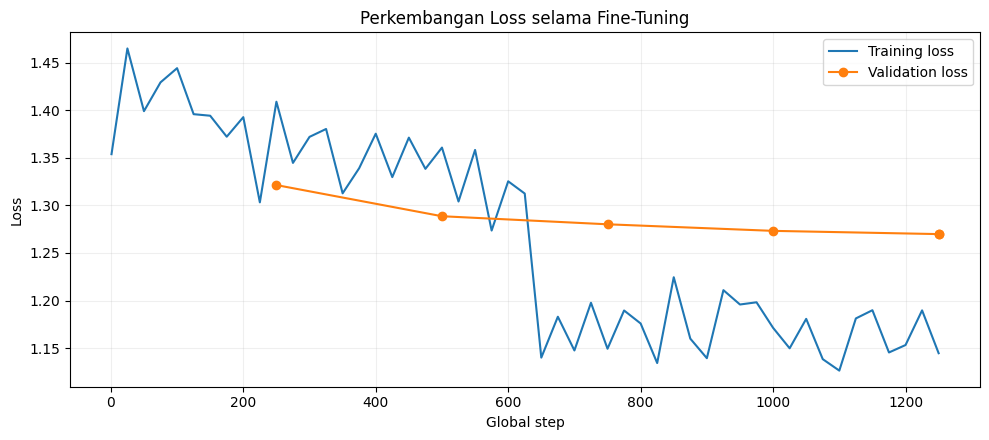

In [16]:
# Salin riwayat log ke DataFrame tanpa menyertakan identitas pengguna.
history_df = pd.DataFrame(trainer.state.log_history)
selected_columns = [
    name for name in ["step", "epoch", "loss", "eval_loss", "learning_rate"]
    if name in history_df.columns
]
display(history_df[selected_columns].tail(12).reset_index(drop=True))

# Gambar loss training dan evaluasi dalam satu figur.
plt.figure(figsize=(10, 4.5))
if "loss" in history_df.columns:
    train_logs = history_df.dropna(subset=["loss"])
    plt.plot(train_logs["step"], train_logs["loss"], label="Training loss")
if "eval_loss" in history_df.columns:
    eval_logs = history_df.dropna(subset=["eval_loss"])
    plt.plot(eval_logs["step"], eval_logs["eval_loss"], marker="o", label="Validation loss")
plt.title("Perkembangan Loss selama Fine-Tuning")
plt.xlabel("Global step")
plt.ylabel("Loss")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## 15. Uji Respons Model Fine-Tuned

Menjalankan beberapa pertanyaan dari test split untuk memastikan model dapat menghasilkan jawaban bahasa Indonesia. Bagian ini hanya *smoke test* inferensi, bukan eksperimen model lain atau klaim peningkatan kualitas.

In [17]:
# Pindahkan model ke mode inference tanpa mengubah bobot hasil training.
FastLanguageModel.for_inference(trainer.model)
trainer.model.eval()

def generate_response(question, max_new_tokens=256):
    # Bentuk prompt dengan chat template yang sama seperti saat training.
    messages = [{"role": "user", "content": str(question)}]
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to("cuda")

    # Hasilkan teks jawaban tanpa perhitungan gradien.
    with torch.inference_mode():
        outputs = trainer.model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.7,
            top_p=0.9,
            repetition_penalty=1.08,
            pad_token_id=tokenizer.eos_token_id,
        )

    # Hanya decode token baru dari assistant.
    answer_ids = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(answer_ids, skip_special_tokens=True).strip()

# Gunakan tiga prompt dari data test yang tidak dipakai melatih model.
for question in test_df["prompt"].head(3):
    print("Pertanyaan:", question)
    print("Jawaban model:", generate_response(question))
    print()

Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Pertanyaan: Diberikan sebuah kalimat, Anda harus membuat versi alternatif yang lebih ringkas dan mudah dipahami. Pesawat lepas landas meskipun angin sangat kencang sehingga membuat sebagian besar orang di area pemirsa menjadi takut.


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Jawaban model: Pesawat lepas landas mengalami kekacauan karena angin kuat, menyebabkan beberapa penonton jatuh sakit.

Pertanyaan: Beritahu saya mengapa orang lebih memilih menggunakan jaringan saraf untuk menyelesaikan masalah?


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Jawaban model: Orang lebih memilih menggunakan jaringan saraf untuk menyelesaikan masalah karena beberapa alasan. Pertama-tama, jaringan saraf adalah model pembelajaran mesin yang dapat belajar dan membuat keputusan berdasarkan data. Ini berarti mereka mampu melakukan tugas yang kompleks seperti analisis data, pemrosesan bahasa alami, dan pengenalan gambar tanpa perlu diprogram secara eksplisit tentang bagaimana melakukannya. Kedua, jaringan saraf sangat fleksibel dan dapat dilatih untuk menangani masalah yang berbeda dengan mudah. Mereka dapat dilatih menggunakan dataset besar dan dapat mengikuti pola dan tren baru dalam data. Ketiga, jaringan saraf memiliki kemampuan adaptif, yang berarti mereka dapat meningkatkan kinerjanya dengan waktu melalui pengulangan. Ini berarti bahwa mereka tidak perlu diperbaiki secara manual setiap kali mereka digunakan. Akhirnya, jaringan saraf merupakan cara efektif untuk menjelajahi dan memahami kompleksitas sistem multivariabel. Dengan menggunakan tekn

## 16. Unggah Model Lengkap ke Hugging Face

Model LoRA hasil training digabung dengan model dasar menjadi **merged 16-bit**, lalu diunggah ke repository Hugging Face. Tahap ini mengikuti pola ekspor pada notebook submission terdahulu, tetapi tanpa menyimpan atau mengunduh model akhir ke komputer pribadi. Proses merge tetap menggunakan **ruang sementara Colab** dan dapat memerlukan RAM serta disk tambahan.

In [18]:
# Buat repository tujuan pada akun yang terautentikasi.
hf_api.create_repo(
    repo_id=HF_REPO_ID,
    repo_type="model",
    private=HF_REPO_PRIVATE,
    exist_ok=True,
    token=HF_TOKEN,
)

# Unggah model yang sudah digabung agar bisa dimuat langsung dari Hub.
trainer.model.push_to_hub_merged(
    HF_REPO_ID,
    tokenizer,
    save_method="merged_16bit",
    token=HF_TOKEN,
)

print("Merged model berhasil diunggah:")
print(f"https://huggingface.co/{HF_REPO_ID}")

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in Lukas16/qwen2-5-1-5b-indonesian-chatbot-sft/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

...

New Data Upload               : |          |  0.00B /  0.00B            

  ...bot-sft/model.safetensors:   1%|          | 24.0MB / 3.09GB            

Validating                    :           |   0%            

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [02:23<00:00, 143.75s/it]


Unsloth: Merge process complete. Saved to `/content/Lukas16/qwen2-5-1-5b-indonesian-chatbot-sft`
Merged model berhasil diunggah:
https://huggingface.co/Lukas16/qwen2-5-1-5b-indonesian-chatbot-sft


## 17. Reload Model and Inference Testing

Bagian ini bertujuan untuk memverifikasi bahwa model hasil *fine-tuning* telah berhasil diunggah ke Hugging Face Hub dan dapat digunakan kembali untuk melakukan inferensi.

Model dimuat langsung dari repository Hugging Face menggunakan kuantisasi 4-bit untuk mengoptimalkan penggunaan memori GPU. Selanjutnya, model diuji menggunakan beberapa pertanyaan berbahasa Indonesia untuk mengamati relevansi, kejelasan, dan kualitas respons yang dihasilkan.

Pengujian menggunakan konfigurasi *deterministic generation* agar respons lebih konsisten. Proses ini tidak melakukan pelatihan ulang maupun mengubah parameter model yang telah disimpan.

In [19]:
# Release previous training model from GPU
if "trainer" in globals():
    del trainer

if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

# Load fine-tuned model from Hugging Face
hub_model, hub_tokenizer = FastLanguageModel.from_pretrained(
    model_name=HF_REPO_ID,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
    token=HF_TOKEN,
)

# Enable inference mode
FastLanguageModel.for_inference(hub_model)
hub_model.eval()

print("Model loaded successfully.")
print(f"Repository: https://huggingface.co/{HF_REPO_ID}")


# Generate response using the fine-tuned model
def generate_response(question, max_new_tokens=256):

    messages = [
        {"role": "user", "content": question}
    ]

    # Apply Qwen chat template
    inputs = hub_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    ).to("cuda")

    # Generate response
    with torch.inference_mode():
        outputs = hub_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.05,
            eos_token_id=hub_tokenizer.eos_token_id,
            pad_token_id=hub_tokenizer.pad_token_id,
            use_cache=True,
        )

    # Decode generated tokens
    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    response = hub_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    return response


# Test questions
test_questions = [
    "Jelaskan apa itu machine learning dengan bahasa yang mudah dipahami.",
    "Apa perbedaan antara artificial intelligence dan machine learning?",
    "Saya ingin belajar Python dari nol. Apa saja langkah yang sebaiknya saya lakukan?"
]

# Run inference and display responses
for i, question in enumerate(test_questions, start=1):
    print(f"\nQuestion {i}: {question}")
    print(f"\nResponse {i}:\n{generate_response(question)}")
    print()

==((====))==  Unsloth 2026.10.8: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Model loaded successfully.
Repository: https://huggingface.co/Lukas16/qwen2-5-1-5b-indonesian-chatbot-sft

Question 1: Jelaskan apa itu machine learning dengan bahasa yang mudah dipahami.


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Response 1:
Machine learning adalah bidang ilmu komputer yang mempelajari bagaimana sistem dapat belajar dan meningkatkan kinerjanya tanpa harus diprogram secara eksplisit untuk melakukan hal itu. Sebagai contoh, jika sebuah perangkat lunak ditugaskan untuk menangani tugas tertentu, ia dapat belajar dari data yang diberikan dan meningkatkan kinerjanya dengan cara yang tidak terlihat manusia. Misalnya, jika sebuah perangkat lunak ditugaskan untuk mengidentifikasi gambar, ia dapat belajar dari berbagai gambar dan akhirnya menjadi lebih baik dalam menemukan objek di dalam gambar. Machine learning digunakan dalam banyak aplikasi, termasuk pengenalan gambar, pengenalan suara, prediksi, dan pemrosesan bahasa alami.


Question 2: Apa perbedaan antara artificial intelligence dan machine learning?


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Response 2:
Artificial Intelligence (AI) dan Machine Learning (ML) adalah dua istilah yang sering digunakan secara bergantian, tetapi memiliki perbedaan kunci dalam arti mereka. AI adalah bidang ilmu yang melibatkan pengembangan sistem komputer yang dapat melakukan tugas yang biasanya memerlukan kecerdasan manusia, seperti pemecahan masalah, pemrosesan bahasa alami, dan pengambilan keputusan. Ini meliputi berbagai teknik, termasuk pembelajaran mesin, pembelajaran bahasa alami, dan pembelajaran mesin untuk game. Sementara itu, Machine Learning adalah subbagian dari AI yang mengacu pada teknik yang digunakan oleh sistem untuk belajar dan meningkatkan diri tanpa harus diprogram secara eksplisit untuk melakukan hal itu. Ini melibatkan penggunaan algoritma untuk menganalisis data dan membuat prediksi atau keputusan berdasarkan informasi tersebut. Dalam kata lain, ML adalah bagian dari AI yang menggunakan algoritma untuk membantu sistem belajar dan meningkatkan diri. Secara ringkas, AI adal